<a href="https://colab.research.google.com/github/priscilasantos1540/Introducao_a_ciencia_de_dados/blob/main/Analise_SINAN_Dengue_Atividade_29_09_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
#Importanda biblioteca Pandas e usando a URL do repositorio do GitHub.
import pandas as pd
url = "https://media.githubusercontent.com/media/priscilasantos1540/Introducao_a_ciencia_de_dados/refs/heads/main/dados/DENGBR26.csv?token=B3AFPGJNJCWYAZWGCKGO663K23UD6"
df = pd.read_csv(url)

/tmp/ipykernel_454/3889857967.py:4: DtypeWarning: Columns (22,44,45,46) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url)


In [6]:
#Identifica a quantidade de linhas e colunas
df.shape

(465323, 121)

In [7]:
# Lista os nomes das características (variáveis) presentes no dataset.
# Essa visualização permite conhecer quais informações estão disponíveis para fazer a classificação.

df.columns

Index(['TP_NOT', 'ID_AGRAVO', 'DT_NOTIFIC', 'SEM_NOT', 'NU_ANO', 'SG_UF_NOT',
       'ID_MUNICIP', 'ID_REGIONA', 'ID_UNIDADE', 'DT_SIN_PRI',
       ...
       'EVIDENCIA', 'PLAQ_MENOR', 'CON_FHD', 'COMPLICA', 'TP_SISTEMA',
       'NDUPLIC_N', 'DT_DIGITA', 'CS_FLXRET', 'FLXRECEBI', 'MIGRADO_W'],
      dtype='object', length=121)

In [8]:
#Verificar os tipos de cada variável do dataset

df.dtypes

,0
TP_NOT,int64
ID_AGRAVO,object
DT_NOTIFIC,object
SEM_NOT,int64
NU_ANO,int64
...,...
NDUPLIC_N,float64
DT_DIGITA,object
CS_FLXRET,int64
FLXRECEBI,float64


In [9]:
# Verifica a quantidade de valores diferentes em cada variável para identificar características categóricas.

df.nunique()

,0
TP_NOT,1
ID_AGRAVO,1
DT_NOTIFIC,267
SEM_NOT,39
NU_ANO,1
...,...
NDUPLIC_N,2
DT_DIGITA,269
CS_FLXRET,2
FLXRECEBI,2


In [10]:
# Mostra os valores existentes nas variáveis que possuem apenas um valor distinto.
# Isso permite verificar se essas variáveis são constantes na base.

for coluna in df.columns:
    if df[coluna].nunique() == 1:
        print(coluna, "->", df[coluna].unique())

TP_NOT -> [2]
ID_AGRAVO -> ['A90']
NU_ANO -> [2026]
DOENCA_TRA -> [ 0. nan]
MANI_HEMOR -> [ 0. nan]
EPISTAXE -> [ 0. nan]
GENGIVO -> [ 0. nan]
METRO -> [ 0. nan]
PETEQUIAS -> [ 0. nan]
HEMATURA -> [ 0. nan]
SANGRAM -> [ 0. nan]
LACO_N -> [ 0. nan]
PLASMATICO -> [ 0. nan]
EVIDENCIA -> [ 0. nan]
PLAQ_MENOR -> [ 0. nan]
CON_FHD -> [ 0. nan]
COMPLICA -> [ 0. nan]
MIGRADO_W -> [ 0. nan]


### O que é o dataset?

O dataset utilizado neste trabalho é uma base de dados do **Sistema de
Informação de Agravos de Notificação (SINAN)**, referente às notificações
de dengue.

A base possui **465.323 instâncias**, correspondentes aos registros de
notificações, e **121 características**, que representam os campos
disponíveis na ficha de notificação.

As características apresentam diferentes naturezas estatísticas,
podendo ser classificadas como nominais, ordinais, discretas e
contínuas, de acordo com o significado e as categorias definidas no
Dicionário de Dados do SINAN Dengue.

As variáveis nominais representam categorias sem ordem natural, como
sexo, UF e município. As variáveis ordinais apresentam categorias que
possuem uma ordem, como escolaridade. As variáveis discretas
representam valores contáveis ou inteiros, como semana e ano. As
variáveis contínuas representam informações em escala temporal, como
as datas registradas na notificação.

### Classificação das características

As características do dataset foram classificadas de acordo com
o significado das variáveis apresentado no Dicionário de Dados
do **SINAN** Dengue.

**A classificação considera quatro tipos:**

- Nominais: representam categorias sem ordem natural.
- Ordinais: representam categorias que possuem uma ordem natural.
- Discretas: representam valores contáveis ou inteiros.
- Contínuas: representam medidas em uma escala contínua. Neste dataset,
  as variáveis temporais (datas) foram consideradas como variáveis contínuas
  de natureza temporal.

### Dicionário das 121 características do banco de dados SINAN – Dengue

| Nº | Característica | Descrição | Tipo de variável |
|---:|---|---|---|
| 1 | `TP_NOT` | Tipo de notificação | Nominal |
| 2 | `ID_AGRAVO` | Código do agravo notificado | Nominal |
| 3 | `DT_NOTIFIC` | Data da notificação | Temporal |
| 4 | `SEM_NOT` | Semana epidemiológica da notificação | Discreta |
| 5 | `NU_ANO` | Ano da notificação | Discreta |
| 6 | `SG_UF_NOT` | Unidade federativa da notificação | Nominal |
| 7 | `ID_MUNICIP` | Código do município da notificação | Nominal |
| 8 | `ID_REGIONA` | Código da região de saúde da notificação | Nominal |
| 9 | `ID_UNIDADE` | Código da unidade de saúde notificadora | Nominal |
| 10 | `DT_SIN_PRI` | Data dos primeiros sintomas | Temporal |
| 11 | `SEM_PRI` | Semana epidemiológica dos primeiros sintomas | Discreta |
| 12 | `ANO_NASC` | Ano de nascimento do paciente | Discreta |
| 13 | `NU_IDADE_N` | Idade codificada do paciente | Discreta codificada |
| 14 | `CS_SEXO` | Sexo do paciente | Nominal |
| 15 | `CS_GESTANT` | Situação gestacional | Nominal |
| 16 | `CS_RACA` | Raça ou cor declarada | Nominal |
| 17 | `CS_ESCOL_N` | Escolaridade do paciente | Ordinal |
| 18 | `SG_UF` | Unidade federativa de residência | Nominal |
| 19 | `ID_MN_RESI` | Código do município de residência | Nominal |
| 20 | `ID_RG_RESI` | Código da região de saúde de residência | Nominal |
| 21 | `ID_PAIS` | Código do país de residência | Nominal |
| 22 | `DT_INVEST` | Data de início da investigação | Temporal |
| 23 | `ID_OCUPA_N` | Código da ocupação do paciente | Nominal |
| 24 | `FEBRE` | Presença de febre | Nominal |
| 25 | `MIALGIA` | Presença de mialgia | Nominal |
| 26 | `CEFALEIA` | Presença de cefaleia | Nominal |
| 27 | `EXANTEMA` | Presença de exantema | Nominal |
| 28 | `VOMITO` | Presença de vômito | Nominal |
| 29 | `NAUSEA` | Presença de náusea | Nominal |
| 30 | `DOR_COSTAS` | Presença de dor nas costas | Nominal |
| 31 | `CONJUNTVIT` | Presença de conjuntivite | Nominal |
| 32 | `ARTRITE` | Presença de artrite | Nominal |
| 33 | `ARTRALGIA` | Presença de artralgia | Nominal |
| 34 | `PETEQUIA_N` | Presença de petéquias | Nominal |
| 35 | `LEUCOPENIA` | Presença de leucopenia | Nominal |
| 36 | `LACO` | Resultado da prova do laço | Nominal |
| 37 | `DOR_RETRO` | Presença de dor retro-orbitária | Nominal |
| 38 | `DIABETES` | Presença de diabetes | Nominal |
| 39 | `HEMATOLOG` | Presença de doença hematológica | Nominal |
| 40 | `HEPATOPAT` | Presença de hepatopatia | Nominal |
| 41 | `RENAL` | Presença de doença renal | Nominal |
| 42 | `HIPERTENSA` | Presença de hipertensão | Nominal |
| 43 | `ACIDO_PEPT` | Presença de doença ácido-péptica | Nominal |
| 44 | `AUTO_IMUNE` | Presença de doença autoimune | Nominal |
| 45 | `DT_CHIK_S1` | Data da primeira coleta para exame de chikungunya | Temporal |
| 46 | `DT_CHIK_S2` | Data da segunda coleta para exame de chikungunya | Temporal |
| 47 | `DT_PRNT` | Data de coleta para exame PRNT | Temporal |
| 48 | `RES_CHIKS1` | Resultado da primeira sorologia para chikungunya | Nominal |
| 49 | `RES_CHIKS2` | Resultado da segunda sorologia para chikungunya | Nominal |
| 50 | `RESUL_PRNT` | Resultado do exame PRNT | Nominal |
| 51 | `DT_SORO` | Data da coleta para sorologia de dengue | Temporal |
| 52 | `RESUL_SORO` | Resultado da sorologia | Nominal |
| 53 | `DT_NS1` | Data da coleta do exame NS1 | Temporal |
| 54 | `RESUL_NS1` | Resultado do exame NS1 | Nominal |
| 55 | `DT_VIRAL` | Data da coleta para isolamento viral | Temporal |
| 56 | `RESUL_VI_N` | Resultado do isolamento viral | Nominal |
| 57 | `DT_PCR` | Data da coleta para exame PCR | Temporal |
| 58 | `RESUL_PCR_` | Resultado do exame PCR | Nominal |
| 59 | `SOROTIPO` | Sorotipo identificado do vírus da dengue | Nominal |
| 60 | `HISTOPA_N` | Resultado do exame histopatológico | Nominal |
| 61 | `IMUNOH_N` | Resultado do exame de imuno-histoquímica | Nominal |
| 62 | `HOSPITALIZ` | Indicação de hospitalização | Nominal |
| 63 | `DT_INTERNA` | Data da internação | Temporal |
| 64 | `UF` | Unidade federativa relacionada à internação | Nominal |
| 65 | `MUNICIPIO` | Município relacionado à internação | Nominal |
| 66 | `TPAUTOCTO` | Indicação de caso autóctone do município de residência | Nominal |
| 67 | `COUFINF` | Unidade federativa provável de infecção | Nominal |
| 68 | `COPAISINF` | País provável de infecção | Nominal |
| 69 | `COMUNINF` | Município provável de infecção | Nominal |
| 70 | `CLASSI_FIN` | Classificação final do caso | Nominal |
| 71 | `CRITERIO` | Critério de confirmação do caso | Nominal |
| 72 | `DOENCA_TRA` | Indicação de doença relacionada ao trabalho | Nominal |
| 73 | `CLINIC_CHIK` | Classificação clínica de chikungunya | Nominal |
| 74 | `EVOLUCAO` | Evolução do caso | Nominal |
| 75 | `DT_OBITO` | Data do óbito | Temporal |
| 76 | `DT_ENCERRA` | Data do encerramento da investigação | Temporal |
| 77 | `ALRM_HIPOT` | Sinal de alarme: hipotensão postural | Nominal |
| 78 | `ALRM_PLAQ` | Sinal de alarme: queda de plaquetas | Nominal |
| 79 | `ALRM_VOM` | Sinal de alarme: vômitos persistentes | Nominal |
| 80 | `ALRM_SANG` | Sinal de alarme: sangramento de mucosas | Nominal |
| 81 | `ALRM_HEMAT` | Sinal de alarme: hematócrito elevado | Nominal |
| 82 | `ALRM_ABDOM` | Sinal de alarme: dor abdominal intensa | Nominal |
| 83 | `ALRM_LETAR` | Sinal de alarme: letargia ou irritabilidade | Nominal |
| 84 | `ALRM_HEPAT` | Sinal de alarme: aumento do fígado | Nominal |
| 85 | `ALRM_LIQ` | Sinal de alarme: acúmulo de líquidos | Nominal |
| 86 | `DT_ALRM` | Data de identificação dos sinais de alarme | Temporal |
| 87 | `GRAV_PULSO` | Sinal de gravidade: pulso débil ou indetectável | Nominal |
| 88 | `GRAV_CONV` | Sinal de gravidade: comprometimento da consciência | Nominal |
| 89 | `GRAV_ENCH` | Sinal de gravidade: tempo de enchimento capilar prolongado | Nominal |
| 90 | `GRAV_INSUF` | Sinal de gravidade: insuficiência respiratória | Nominal |
| 91 | `GRAV_TAQUI` | Sinal de gravidade: taquicardia | Nominal |
| 92 | `GRAV_EXTRE` | Sinal de gravidade: extremidades frias | Nominal |
| 93 | `GRAV_HIPOT` | Sinal de gravidade: hipotensão arterial | Nominal |
| 94 | `GRAV_HEMAT` | Sinal de gravidade: hematócrito elevado associado a choque | Nominal |
| 95 | `GRAV_MELEN` | Sinal de gravidade: melena | Nominal |
| 96 | `GRAV_METRO` | Sinal de gravidade: metrorragia | Nominal |
| 97 | `GRAV_SANG` | Sinal de gravidade: hemorragia grave | Nominal |
| 98 | `GRAV_AST` | Sinal de gravidade: aumento de AST/ALT | Nominal |
| 99 | `GRAV_MIOC` | Sinal de gravidade: miocardite | Nominal |
| 100 | `GRAV_CONSC` | Sinal de gravidade: alteração da consciência | Nominal |
| 101 | `GRAV_ORGAO` | Sinal de gravidade: comprometimento grave de órgãos | Nominal |
| 102 | `DT_GRAV` | Data de identificação da gravidade | Temporal |
| 103 | `MANI_HEMOR` | Manifestação hemorrágica | Nominal |
| 104 | `EPISTAXE` | Presença de epistaxe | Nominal |
| 105 | `GENGIVO` | Presença de sangramento gengival | Nominal |
| 106 | `METRO` | Presença de metrorragia | Nominal |
| 107 | `PETEQUIAS` | Presença de petéquias | Nominal |
| 108 | `HEMATURA` | Presença de hematúria | Nominal |
| 109 | `SANGRAM` | Presença de outras manifestações hemorrágicas | Nominal |
| 110 | `LACO_N` | Resultado da prova do laço | Nominal |
| 111 | `PLASMATICO` | Evidência de extravasamento plasmático | Nominal |
| 112 | `EVIDENCIA` | Evidência de dengue grave | Nominal |
| 113 | `PLAQ_MENOR` | Contagem de plaquetas abaixo do limite indicado | Nominal |
| 114 | `CON_FHD` | Critérios compatíveis com febre hemorrágica da dengue | Nominal |
| 115 | `COMPLICA` | Complicações do caso | Nominal |
| 116 | `TP_SISTEMA` | Sistema de origem do registro | Nominal |
| 117 | `NDUPLIC_N` | Indicador de duplicidade da notificação | Nominal |
| 118 | `DT_DIGITA` | Data de digitação do registro | Temporal |
| 119 | `CS_FLXRET` | Situação do registro no fluxo de retorno | Nominal |
| 120 | `FLXRECEBI` | Informação de recebimento pelo fluxo de retorno | Nominal |
| 121 | `MIGRADO_W` | Indicador de migração do registro do Sinan Windows | Nominal |


**Resumo da classificação:**

As características do conjunto de dados são predominantemente nominais, incluindo variáveis categóricas e códigos de identificação. Também estão presentes características ordinais, discretas e temporais, como as relacionadas à escolaridade, idade, semanas epidemiológicas e datas dos registros. Não foram identificadas características quantitativas contínuas entre as variáveis analisadas.

In [11]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Cria uma cópia para as visualizações para preservar a base original.
df_vis = df.copy()

# Converte as datas para o formato de data.
for coluna in ["DT_NOTIFIC", "DT_SIN_PRI"]:
    df_vis[coluna] = pd.to_datetime(
        df_vis[coluna],
        errors="coerce",
        dayfirst=True
    )

# Calcula o intervalo entre os primeiros sintomas e a data da notificação, em dias.
df_vis["DIAS_ATE_NOTIFICACAO"] = (
    df_vis["DT_NOTIFIC"] - df_vis["DT_SIN_PRI"]
).dt.days

print("Dimensões da base:", df_vis.shape)
df_vis.head()


Dimensões da base: (465323, 122)


/tmp/ipykernel_454/2687667268.py:11: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_vis[coluna] = pd.to_datetime(
/tmp/ipykernel_454/2687667268.py:11: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_vis[coluna] = pd.to_datetime(


,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,DT_SIN_PRI,...,PLAQ_MENOR,CON_FHD,COMPLICA,TP_SISTEMA,NDUPLIC_N,DT_DIGITA,CS_FLXRET,FLXRECEBI,MIGRADO_W,DIAS_ATE_NOTIFICACAO
0,2,A90,2026-05-19,202620,2026,32,320400,32001.0,2448653.0,2026-05-14,...,0.0,0.0,0.0,0.0,0.0,2025-11-08,0,0.0,0.0,5
1,2,A90,2026-01-05,202601,2026,32,320500,32002.0,2499495.0,2026-01-04,...,0.0,0.0,0.0,0.0,0.0,2026-01-05,0,0.0,0.0,1
2,2,A90,2026-01-05,202601,2026,32,320500,32002.0,2522772.0,2026-01-05,...,0.0,0.0,0.0,0.0,0.0,2026-01-05,0,0.0,0.0,0
3,2,A90,2026-01-05,202601,2026,32,320500,32002.0,7838131.0,2026-01-04,...,0.0,0.0,0.0,0.0,0.0,2026-01-05,0,0.0,0.0,1
4,2,A90,2026-01-05,202601,2026,32,320530,32002.0,11789.0,2026-01-05,...,0.0,0.0,0.0,0.0,0.0,2026-01-05,0,0.0,0.0,0


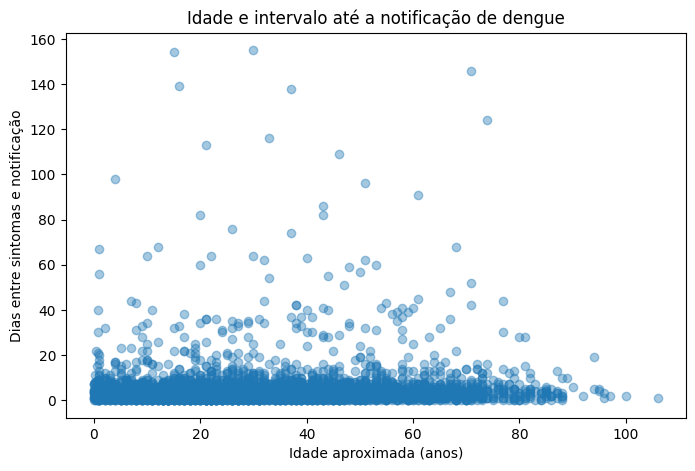

In [12]:

# Altera NU_IDADE_N para uma idade aproximada em anos.
# 1 = hora, 2 = dia, 3 = mês, 4 = ano.

def converter_idade(valor):
    if pd.isna(valor):
        return float("nan")

    try:
        codigo = int(float(valor))
    except (ValueError, TypeError, OverflowError):
        return float("nan")

    unidade = codigo // 1000
    idade = codigo % 1000

    if unidade == 1:
        return idade / (24 * 365.25)
    elif unidade == 2:
        return idade / 365.25
    elif unidade == 3:
        return idade / 12
    elif unidade == 4:
        return idade

    return float("nan")


df_vis["IDADE_ANOS"] = df_vis["NU_IDADE_N"].apply(converter_idade)

# Seleciona registros com valores disponíveis.
dados_grafico = df_vis.dropna(
    subset=["IDADE_ANOS", "DIAS_ATE_NOTIFICACAO"]
)

# Retira intervalos negativos para este gráfico.
dados_grafico = dados_grafico[
    dados_grafico["DIAS_ATE_NOTIFICACAO"] >= 0
]

# Limita a quantidade de pontos exibidos.
amostra = dados_grafico.sample(
    n=min(5000, len(dados_grafico)),
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.scatter(
    amostra["IDADE_ANOS"],
    amostra["DIAS_ATE_NOTIFICACAO"],
    alpha=0.4
)

plt.xlabel("Idade aproximada (anos)")
plt.ylabel("Dias entre sintomas e notificação")
plt.title("Idade e intervalo até a notificação de dengue")

plt.show()


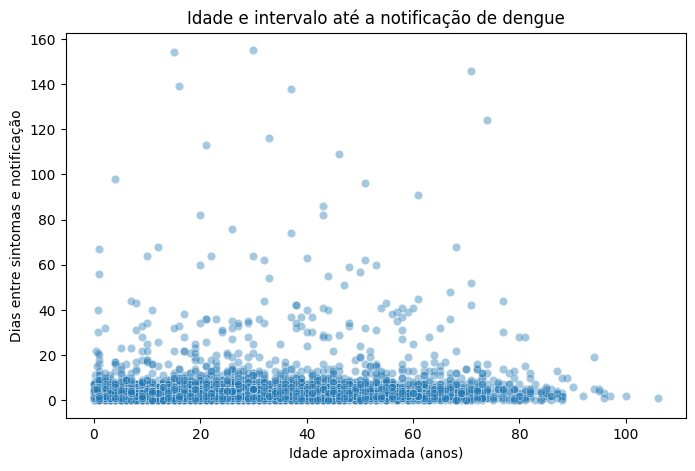

In [13]:
#Gráfico de dispersão — Matplotlib

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=amostra,
    x="IDADE_ANOS",
    y="DIAS_ATE_NOTIFICACAO",
    alpha=0.4
)

plt.title("Idade e intervalo até a notificação de dengue")
plt.xlabel("Idade aproximada (anos)")
plt.ylabel("Dias entre sintomas e notificação")

plt.show()


In [14]:
#Gráfico de dispersão — Seaborn

fig = px.scatter(
    amostra,
    x="IDADE_ANOS",
    y="DIAS_ATE_NOTIFICACAO",
    color="CS_SEXO",
    title="Idade e intervalo até a notificação, por sexo",
    labels={
        "IDADE_ANOS": "Idade aproximada (anos)",
        "DIAS_ATE_NOTIFICACAO": "Dias até a notificação",
        "CS_SEXO": "Sexo informado"
    },
    opacity=0.6
)

fig.show()


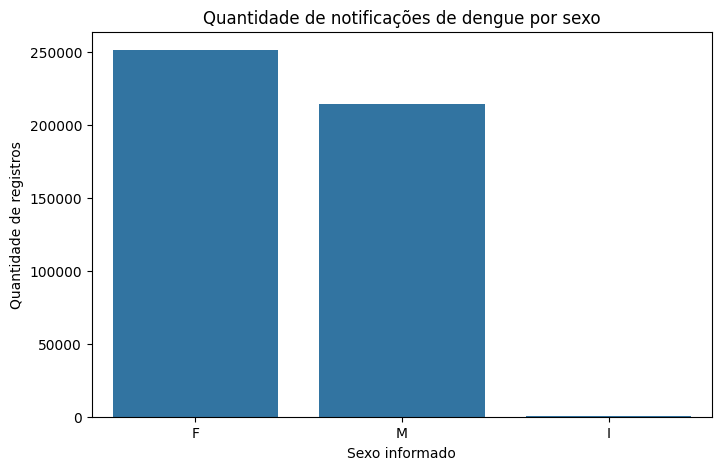

In [15]:
#Gráfico interativo — Plotly

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_vis,
    x="CS_SEXO"
)

plt.title("Quantidade de notificações de dengue por sexo")
plt.xlabel("Sexo informado")
plt.ylabel("Quantidade de registros")

plt.show()


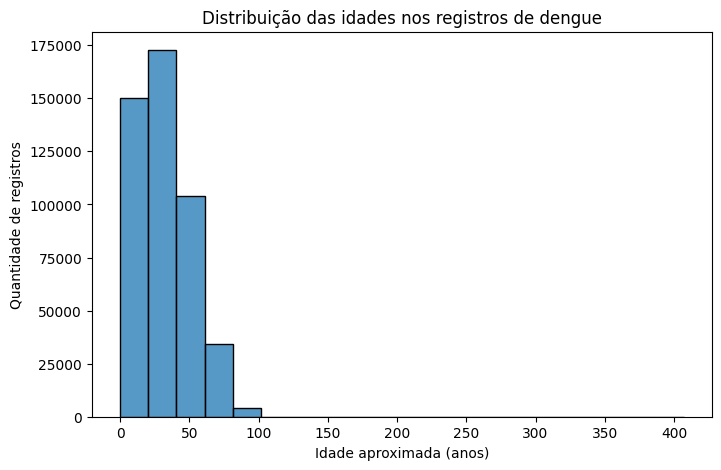

In [16]:
#Histograma — distribuição das idades

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_vis,
    x="IDADE_ANOS",
    bins=20
)

plt.title("Distribuição das idades nos registros de dengue")
plt.xlabel("Idade aproximada (anos)")
plt.ylabel("Quantidade de registros")

plt.show()


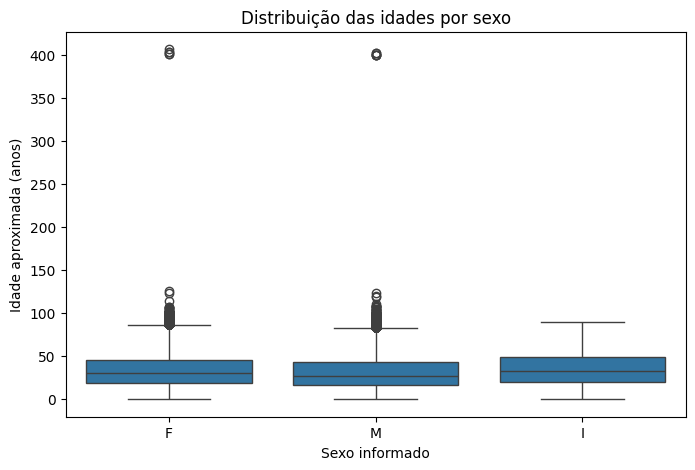

In [17]:
#Boxplot — comparação de idades por sexo

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_vis,
    x="CS_SEXO",
    y="IDADE_ANOS"
)

plt.title("Distribuição das idades por sexo")
plt.xlabel("Sexo informado")
plt.ylabel("Idade aproximada (anos)")

plt.show()


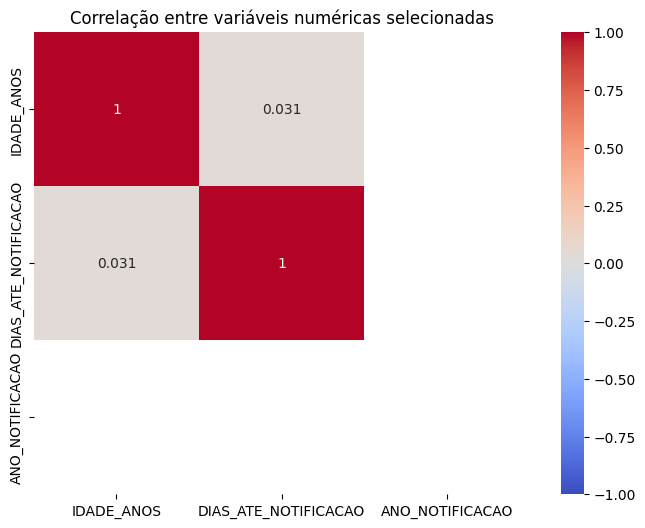

In [18]:
#Heatmap de correlação

df_vis["ANO_NOTIFICACAO"] = df_vis["DT_NOTIFIC"].dt.year

variaveis_numericas = df_vis[
    ["IDADE_ANOS", "DIAS_ATE_NOTIFICACAO", "ANO_NOTIFICACAO"]
]

correlacao = variaveis_numericas.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlação entre variáveis numéricas selecionadas")

plt.show()


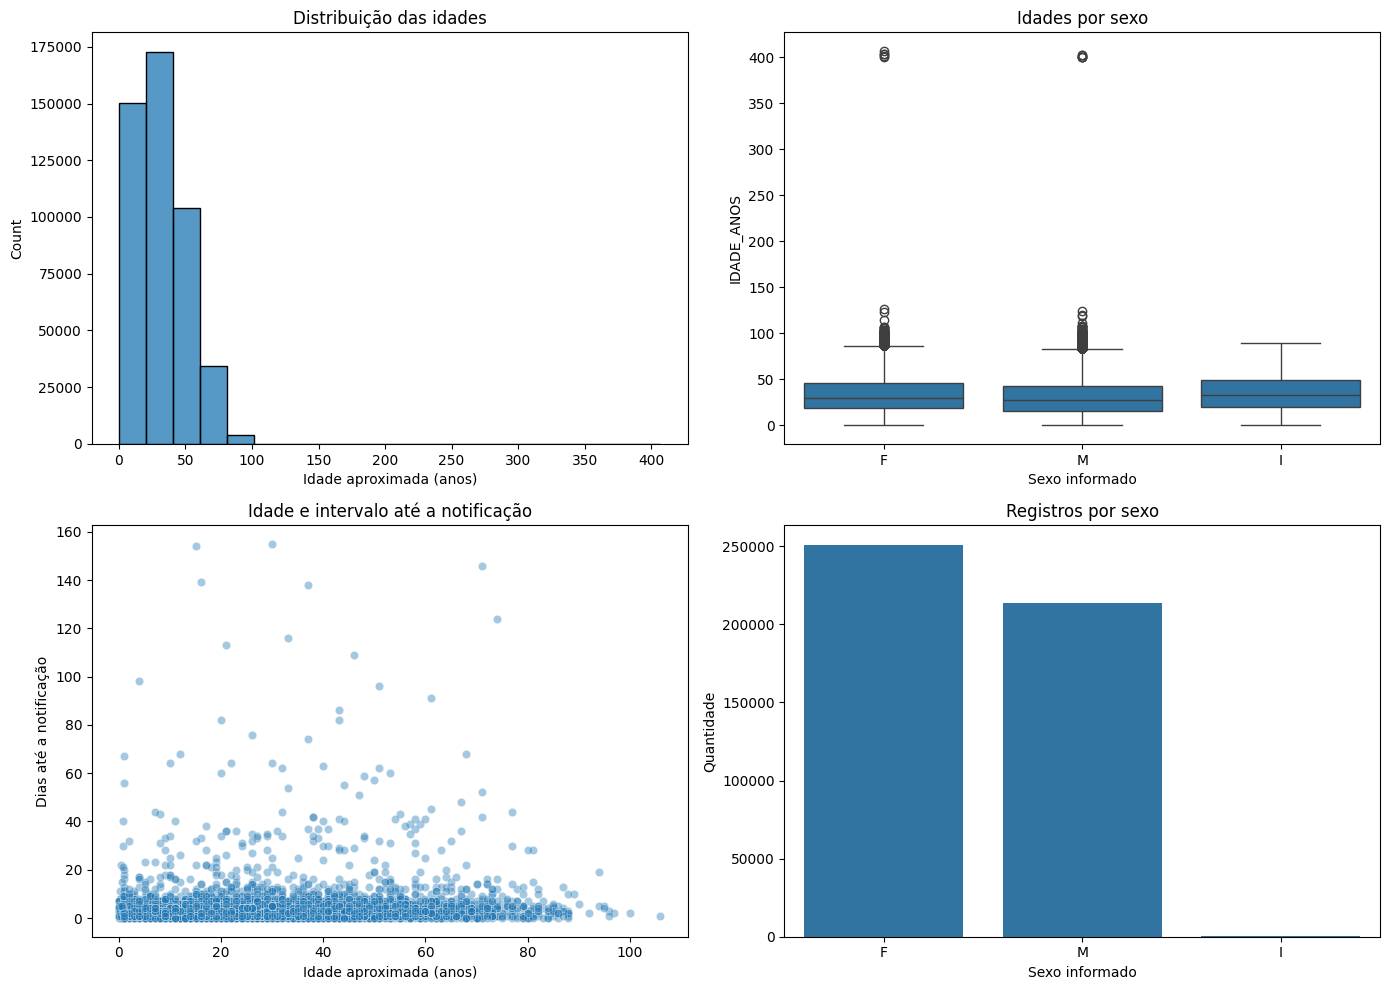

In [19]:
#Dashboard com quatro gráficos

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribuição das idades
sns.histplot(
    data=df_vis,
    x="IDADE_ANOS",
    bins=20,
    ax=ax[0, 0]
)
ax[0, 0].set_title("Distribuição das idades")
ax[0, 0].set_xlabel("Idade aproximada (anos)")

# 2. Idades por sexo
sns.boxplot(
    data=df_vis,
    x="CS_SEXO",
    y="IDADE_ANOS",
    ax=ax[0, 1]
)
ax[0, 1].set_title("Idades por sexo")
ax[0, 1].set_xlabel("Sexo informado")

# 3. Idade versus intervalo até a notificação
sns.scatterplot(
    data=amostra,
    x="IDADE_ANOS",
    y="DIAS_ATE_NOTIFICACAO",
    alpha=0.4,
    ax=ax[1, 0]
)
ax[1, 0].set_title("Idade e intervalo até a notificação")
ax[1, 0].set_xlabel("Idade aproximada (anos)")
ax[1, 0].set_ylabel("Dias até a notificação")

# 4. Quantidade de registros por sexo
sns.countplot(
    data=df_vis,
    x="CS_SEXO",
    ax=ax[1, 1]
)
ax[1, 1].set_title("Registros por sexo")
ax[1, 1].set_xlabel("Sexo informado")
ax[1, 1].set_ylabel("Quantidade")

plt.tight_layout()
plt.show()


In [20]:
print("1. Registros por sexo:")
print(df_vis["CS_SEXO"].value_counts(dropna=False))

print("\n2. Faixas etárias com mais registros:")
print(
    pd.cut(
        df_vis["IDADE_ANOS"],
        bins=[0, 12, 18, 30, 45, 60, 120],
        right=False,
        labels=[
            "0 a 11 anos",
            "12 a 17 anos",
            "18 a 29 anos",
            "30 a 44 anos",
            "45 a 59 anos",
            "60 anos ou mais"
        ]
    ).value_counts(sort=False)
)

print("\n3. Estatísticas do intervalo entre sintomas e notificação:")
print(
    df_vis["DIAS_ATE_NOTIFICACAO"]
    .describe()
    .round(2)
)


1. Registros por sexo:
CS_SEXO
F    251047
M    213969
I       307
Name: count, dtype: int64

2. Faixas etárias com mais registros:
IDADE_ANOS
0 a 11 anos         69786
12 a 17 anos        48519
18 a 29 anos       121904
30 a 44 anos       109116
45 a 59 anos        71026
60 anos ou mais     44952
Name: count, dtype: int64

3. Estatísticas do intervalo entre sintomas e notificação:
count    465323.00
mean          4.48
std           8.41
min           0.00
25%           1.00
50%           3.00
75%           5.00
max         246.00
Name: DIAS_ATE_NOTIFICACAO, dtype: float64


# Storytelling com Dados — Análise das notificações de dengue do SINAN

## 1. Contexto

A dengue é uma doença de notificação compulsória, e os dados registrados no Sistema de Informação de Agravos de Notificação (SINAN) auxiliam no acompanhamento epidemiológico da doença. Neste trabalho, foi utilizada uma base de dados do SINAN referente à dengue, composta por 465.323 registros e 121 características. O conjunto contém informações como idade, sexo, datas de notificação, início dos sintomas, sintomas apresentados e evolução dos casos.

## 2. Análise e visualização

Foram elaborados gráficos de dispersão, barras, histograma, boxplot e mapa de calor, além de um dashboard. Essas visualizações permitem explorar diferentes aspectos dos registros.

O gráfico de dispersão permite investigar a relação entre a idade aproximada dos pacientes e o intervalo entre o início dos sintomas e a notificação. O gráfico de barras permite comparar a quantidade de registros entre as categorias de sexo informado. Já o histograma e o boxplot ajudam a observar a distribuição das idades e suas diferenças entre grupos.

O mapa de calor permite analisar as correlações entre as variáveis numéricas selecionadas. Entretanto, uma correlação indica associação estatística e não comprova que uma variável cause alterações em outra.

## 3. Principais observações

A utilização de diferentes gráficos proporciona uma visão complementar da base de dados. Enquanto algumas visualizações ajudam a comparar categorias, outras permitem investigar distribuições, possíveis valores extremos e associações entre variáveis.

O dashboard reúne essas perspectivas em uma única visualização, facilitando a consulta simultânea dos indicadores selecionados.

Para identificar quais categorias apresentam maior quantidade de registros, quais faixas etárias concentram mais observações e quais associações se destacam, é necessário considerar os valores efetivamente apresentados pelos gráficos.

## 4. Conclusão

A visualização de dados é uma etapa importante da análise exploratória, pois facilita a identificação de padrões e a comunicação dos resultados. No conjunto de dados do SINAN, os gráficos ajudam a explorar as características dos registros de dengue e podem orientar investigações posteriores.

As conclusões devem considerar a qualidade dos dados, os valores ausentes, a forma como as variáveis foram codificadas e o período abrangido pelo arquivo. Além disso, os resultados descrevem os registros analisados e não devem ser generalizados automaticamente para toda a população brasileira.

Assim, o uso combinado de Matplotlib, Seaborn e Plotly demonstra como diferentes ferramentas podem apoiar a exploração, a interpretação e a apresentação de dados epidemiológicos.